<a href="https://colab.research.google.com/github/bu11ymaguire/SKT_FLY_AI_8/blob/main/12_26_vol1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#선형회귀 - TensorFlow

In [4]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import tensorflow as tf
import keras

In [6]:
import random
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
keras.utils.set_random_seed(SEED)

np.set_printoptions(precision=4, suppress=True, linewidth=200)

# 데이터 준비

In [7]:
!wget 'https://raw.githubusercontent.com/devdio/flyai_datasets/refs/heads/main/nn/points50k.csv'

--2025-12-26 02:51:49--  https://raw.githubusercontent.com/devdio/flyai_datasets/refs/heads/main/nn/points50k.csv
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.110.133, 185.199.109.133, 185.199.111.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.110.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 561913 (549K) [text/plain]
Saving to: ‘points50k.csv’

points50k.csv       100%[===================>] 548.74K  --.-KB/s    in 0.04s   

2025-12-26 02:51:49 (12.5 MB/s) - ‘points50k.csv’ saved [561913/561913]



In [9]:
df = pd.read_csv('points50k.csv')

In [10]:
df.head()

,x,y
0,-9.88,-11.68
1,2.99,3.26
2,-7.47,-8.47
3,-4.71,-1.91
4,1.17,4.14


## 시각화

In [11]:
x = df['x']
y = df['y']

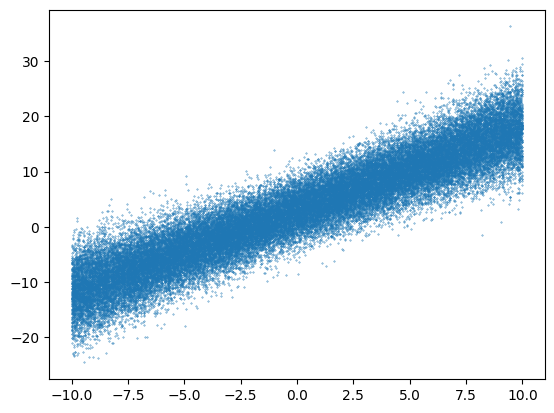

In [13]:
plt.scatter(x, y, s = 0.1)
plt.show()

In [14]:
from sklearn.model_selection import train_test_split

x_train, x_val, y_train, y_val = train_test_split(x,y,test_size=0.1,random_state=SEED)

In [16]:
x_train.shape, x_val.shape, y_train.shape, y_val.shape

((45000,), (5000,), (45000,), (5000,))

# 텐서플로우

In [17]:
x_train = tf.constant(x_train, dtype = tf.float32)
y_train = tf.constant(y_train, dtype = tf.float32)
x_val = tf.constant(x_val, dtype = tf.float32)
y_val = tf.constant(y_val, dtype = tf.float32)

##데이터 로딩 함수

In [19]:
g = tf.random.Generator.from_seed(SEED)

def get_batch(x, y, batch_size = 16):
  data_length = tf.shape(x)[0]
  indices = g.uniform(shape = (batch_size,) , minval=0, maxval = data_length, dtype= tf.int32)
  return tf.gather(x, indices), tf.gather(y, indices)

In [20]:
x_batch, y_batch = get_batch(x_train, y_train)
x_batch.shape, y_batch.shape

(TensorShape([16]), TensorShape([16]))

##학습

In [28]:
a_var = tf.Variable(3.0, dtype = tf.float32, name = "a_var")
b_var = tf.Variable(0.0, dtype = tf.float32, name = "b_var")

learning_rate = 0.001

In [32]:
num_steps = 5000

for step in range(num_steps):
  x_batch, y_batch = get_batch(x_train, y_train)

  with tf.GradientTape() as tape:
    train_pred = a_var * x_batch + b_var
    loss = tf.reduce_mean(tf.square(y_batch - train_pred))

    val_pred = a_var * x_val + b_var
    val_loss = tf.reduce_mean(tf.square(y_val - val_pred))

  gradients = tape.gradient(loss, [a_var,b_var])
  grad_a = gradients[0]
  grad_b = gradients[1]

  a_var.assign_sub(learning_rate * grad_a)
  b_var.assign_sub(learning_rate * grad_b)

  print(f"{step}, val_loss : {val_loss.numpy()}")

0, val_loss : 12.111987113952637
1, val_loss : 12.117897033691406
2, val_loss : 12.114303588867188
3, val_loss : 12.112948417663574
4, val_loss : 12.119650840759277
5, val_loss : 12.135993957519531
6, val_loss : 12.128344535827637
7, val_loss : 12.122734069824219
8, val_loss : 12.120797157287598
9, val_loss : 12.116151809692383
10, val_loss : 12.11050796508789
11, val_loss : 12.109848022460938
12, val_loss : 12.112107276916504
13, val_loss : 12.119595527648926
14, val_loss : 12.109899520874023
15, val_loss : 12.109898567199707
16, val_loss : 12.1126070022583
17, val_loss : 12.110427856445312
18, val_loss : 12.11558723449707
19, val_loss : 12.120296478271484
20, val_loss : 12.117566108703613
21, val_loss : 12.156511306762695
22, val_loss : 12.224230766296387
23, val_loss : 12.172689437866211
24, val_loss : 12.136406898498535
25, val_loss : 12.110872268676758
26, val_loss : 12.115423202514648
27, val_loss : 12.118720054626465
28, val_loss : 12.123688697814941
29, val_loss : 12.1219425201